# Process A – visual analysis (README)

**What this notebook is:** plots to *see* process A (161 labelled batches, 161 test batches, 11 sensor variables, no missing values). Grey = accepted, red = rejected, blue = test (unlabelled). Sections below follow the plots; the key findings are here.

## Key findings

1. **25 % of batches are rejected (40 / 161).** Batches come in two typical lengths, ~2380 and ~2720 timesteps, in both classes; a handful are much shorter (`A_232` 196 – rejected, `A_149` 1166 – accepted, `A_215` 1720 – rejected, `A_285` 1794 – accepted). Length alone says little (AUC ≈ 0.63).
2. **Within a batch the process is flat.** Apart from a ramp at the start and end of `density`, variables are stationary noise around a batch-specific level. The information is therefore in *per-batch levels and noise*, not in a time pattern.
3. **A group of rejected batches are level outliers**, often with the *same* offsets repeating (sensor/calibration-like states): `temperature_4` ≈ −15.3 (`A_051`, `A_256`, `A_263`, `A_274`) or ≈ −9.3 (`A_048`, `A_215`, `A_226`); `flow_rate_1` ≈ 121 (4 batches) or ≈ 137 (2); `temperature_3` ≈ 21.7 (3) or > 28 (4). Taking the median per batch and flagging any variable whose distance from the accepted centre exceeds the largest distance among accepted batches (the baseline rule) catches **22 of 40** rejected batches, with **8 / 121** false alarms under leave-one-out (§5).
4. **The other 18 rejected batches look normal in level – the signal is `temperature_1` noise.** Rejected batches have higher (median 14.3 vs 13.9) and, above all, *noisier* `temperature_1`. Its within-batch std is the best single feature (AUC 0.72): **9 rejected batches have std > 0.25, while the highest accepted batch has 0.24**. These 9 are exactly 9 of the 18 batches the level rule misses (`A_017, A_065, A_104, A_169, A_176, A_189, A_197, A_244, A_298`). Level rule OR `temperature_1_std > 0.25` → **31 of 40** rejected. ⚠ The 0.25 cut was chosen by looking at these plots, so it is optimistic: validate it before trusting it.
5. **`pressure_2` and `pressure_4` do not separate the classes at all** (no rejected batch flagged by either), and 9 rejected batches (~1/4) remain unexplained by any variable we looked at.
6. **No drift over the campaign.** Rejected batches are spread across batch numbers 1–320 (rolling rejection rate wanders around 25 %, no trend) and the test batches are interleaved with the calibration ones.
7. **Test looks like calibration.** Batch-level distributions agree, and the test set contains the same outlier states (e.g. `temperature_4` ≈ −15.3, `flow_rate_1` ≈ 121), so the level rule transfers.
8. **Batches 101–104:** `A_101`, `A_103` accepted, `A_104` rejected, `A_102` is a *test* batch. `A_104` stands out in `temperature_1`: it climbs steadily from ≈ 13.6 to ≈ 14.5 with a step near 80 % of the batch (and has high `temperature_1` noise, `std` > 0.25), plus a higher `density`/`pressure_1` level. `A_101` and `A_102` have a high but stable `temperature_1` (~14.7–14.8); `A_103` is typical.
9. **In 2D (PCA) the classes overlap heavily**; rejected batches are mostly the far-away points on the edges. A linear picture will not separate them – a model needs the specific features above.

## Caveats
- Everything here is exploratory and in-sample; no model was fitted.
- Batch-level summaries use the median/std over the whole run; they would be affected by the short batches.
- Time axis is *normalised* (0–1) because batch lengths differ.

*Data is read through a parquet cache in `/home/renku/work/parquet_cache/` (outside the repo).*


---
## 0. Setup & data

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.preprocessing import RobustScaler
%matplotlib inline
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,"axes.titleweight":"bold","axes.titlesize":10,"legend.frameon":False})
GREY,RED,BLUE="#8a8f98","#d62728","#1f77b4"; PAL={"accepted":GREY,"rejected":RED}
ROOT=Path("/home/renku/work/input-data/Project 2 - BRPMM"); CACHE=Path("/home/renku/work/parquet_cache"); CACHE.mkdir(exist_ok=True)
def read_cached(csv,name):
    pq=CACHE/f"{name}.parquet"
    if pq.exists() and pq.stat().st_mtime>=Path(csv).stat().st_mtime: return pd.read_parquet(pq)
    df=pd.read_csv(csv); df.to_parquet(pq,index=False); return df
def load(p):
    b=ROOT/f"process {p}"
    cal=read_cached(b/"calibration data/calibration_data.csv",f"{p}_cal"); lab=pd.read_csv(b/"calibration data/calibration_labels.csv")
    test=read_cached(b/"test data/test_data.csv",f"{p}_test")
    for d in (cal,test): d["t"]=d.groupby("batch_id").cumcount(); d["tn"]=d.t/d.groupby("batch_id").t.transform("max")  # tn = normalised time 0..1
    return cal.merge(lab,on="batch_id"),lab,test
def tensor(df,vars_,n=300):
    """resample every batch to n points on normalised time -> {var: array(batches, n)}"""
    g=np.linspace(0,1,n); ids=df.batch_id.unique(); out={v:np.empty((len(ids),n)) for v in vars_}
    for i,(b,x) in enumerate(df.groupby("batch_id",sort=False)):
        for v in vars_: out[v][i]=np.interp(g,x.tn.values,x[v].values)
    return g,list(ids),out
def robust_ylim(a,lo=1,hi=99,pad=.15):
    l,h=np.nanpercentile(a,[lo,hi]); d=(h-l) or 1; return l-pad*d,h+pad*d
def savefig_title(fig,t,y=1.0): fig.suptitle(t,y=y,fontsize=13,fontweight="bold")

cal,lab,test=load("A")
V=[c for c in cal.columns if c not in("batch_id","t","tn","label")]
y=lab.set_index("batch_id").label
n_cal=cal.groupby("batch_id").size(); n_test=test.groupby("batch_id").size()
print(f"{len(V)} variables | {cal.batch_id.nunique()} calibration batches | {test.batch_id.nunique()} test batches")
from scipy.ndimage import uniform_filter1d
sm=lambda a,w=9: uniform_filter1d(a,w,axis=-1,mode='nearest')   # light smoothing for display only
g,ids,Xc=tensor(cal,V); idt=ids; yc=y.reindex(ids).values; gt,idst,Xt=tensor(test,V)
acc=yc=="accepted"; rej=~acc
# per-batch summary features
med=cal.groupby("batch_id")[V].median().loc[ids]; sd=cal.groupby("batch_id")[V].std().loc[ids]
tmed=test.groupby("batch_id")[V].median().loc[idst]
bnum=lambda ids:np.array([int(b.split("_")[1]) for b in ids])

11 variables | 161 calibration batches | 161 test batches


## 1. Class balance and batch length
How many batches are rejected, and does batch length say anything?

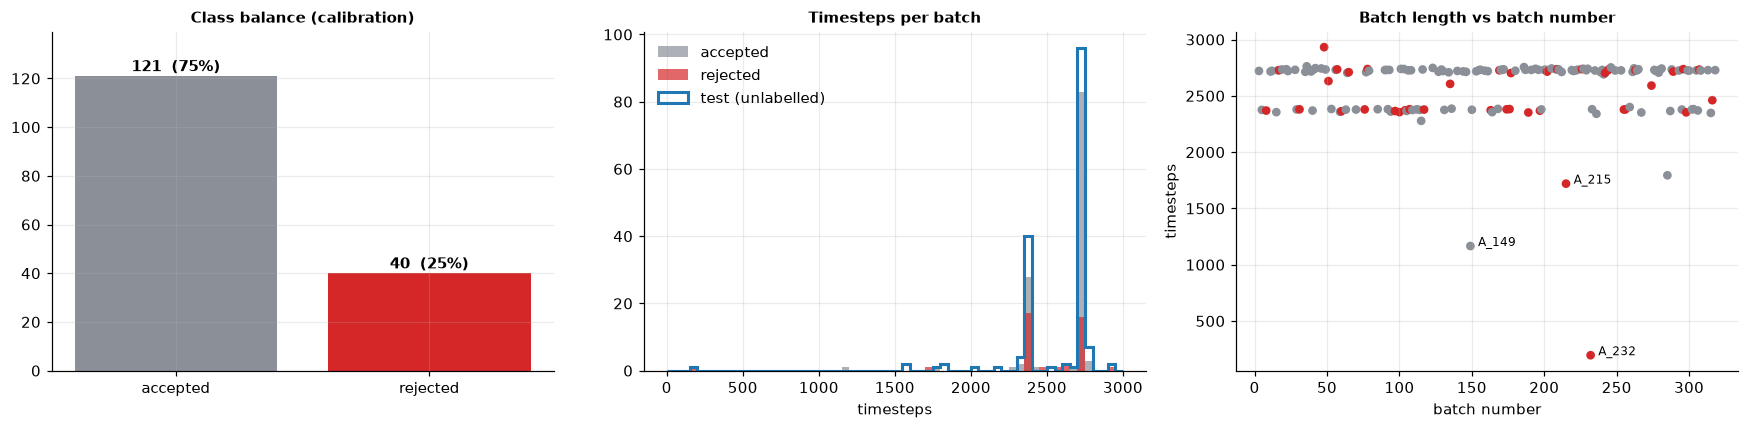

In [2]:
fig,ax=plt.subplots(1,3,figsize=(16,4))
vc=y.value_counts(); ax[0].bar(vc.index,vc.values,color=[PAL[k] for k in vc.index])
for i,(k,v) in enumerate(vc.items()): ax[0].text(i,v+2,f"{v}  ({100*v/vc.sum():.0f}%)",ha="center",fontweight="bold")
ax[0].set_title("Class balance (calibration)"); ax[0].set_ylim(0,vc.max()*1.15)
for k in PAL: ax[1].hist(n_cal[y.reindex(n_cal.index)==k],bins=np.arange(0,3050,50),color=PAL[k],alpha=.7,label=k)
ax[1].hist(n_test,bins=np.arange(0,3050,50),histtype="step",color=BLUE,lw=2,label="test (unlabelled)")
ax[1].set_title("Timesteps per batch"); ax[1].set_xlabel("timesteps"); ax[1].legend()
c=[PAL[k] for k in y.reindex(n_cal.index)]; ax[2].scatter(bnum(n_cal.index),n_cal.values,c=c,s=22)
ax[2].set_title("Batch length vs batch number"); ax[2].set_xlabel("batch number"); ax[2].set_ylabel("timesteps")
for b in n_cal.nsmallest(3).index: ax[2].annotate(b,(bnum([b])[0],n_cal[b]),fontsize=8,xytext=(5,0),textcoords="offset points")
plt.tight_layout(); plt.show()

## 2. Every variable over (normalised) time
Batches have different lengths, so time is rescaled to 0–1; curves are lightly smoothed (9-point moving average) so the noisy variables stay readable. **Grey band** = middle 80 % of accepted batches, **grey line** = accepted median, **red lines** = individual rejected batches. The y-axis is zoomed to the bulk of the data (1st–99th percentile), so extreme outliers run off the plot — they are shown in §5.

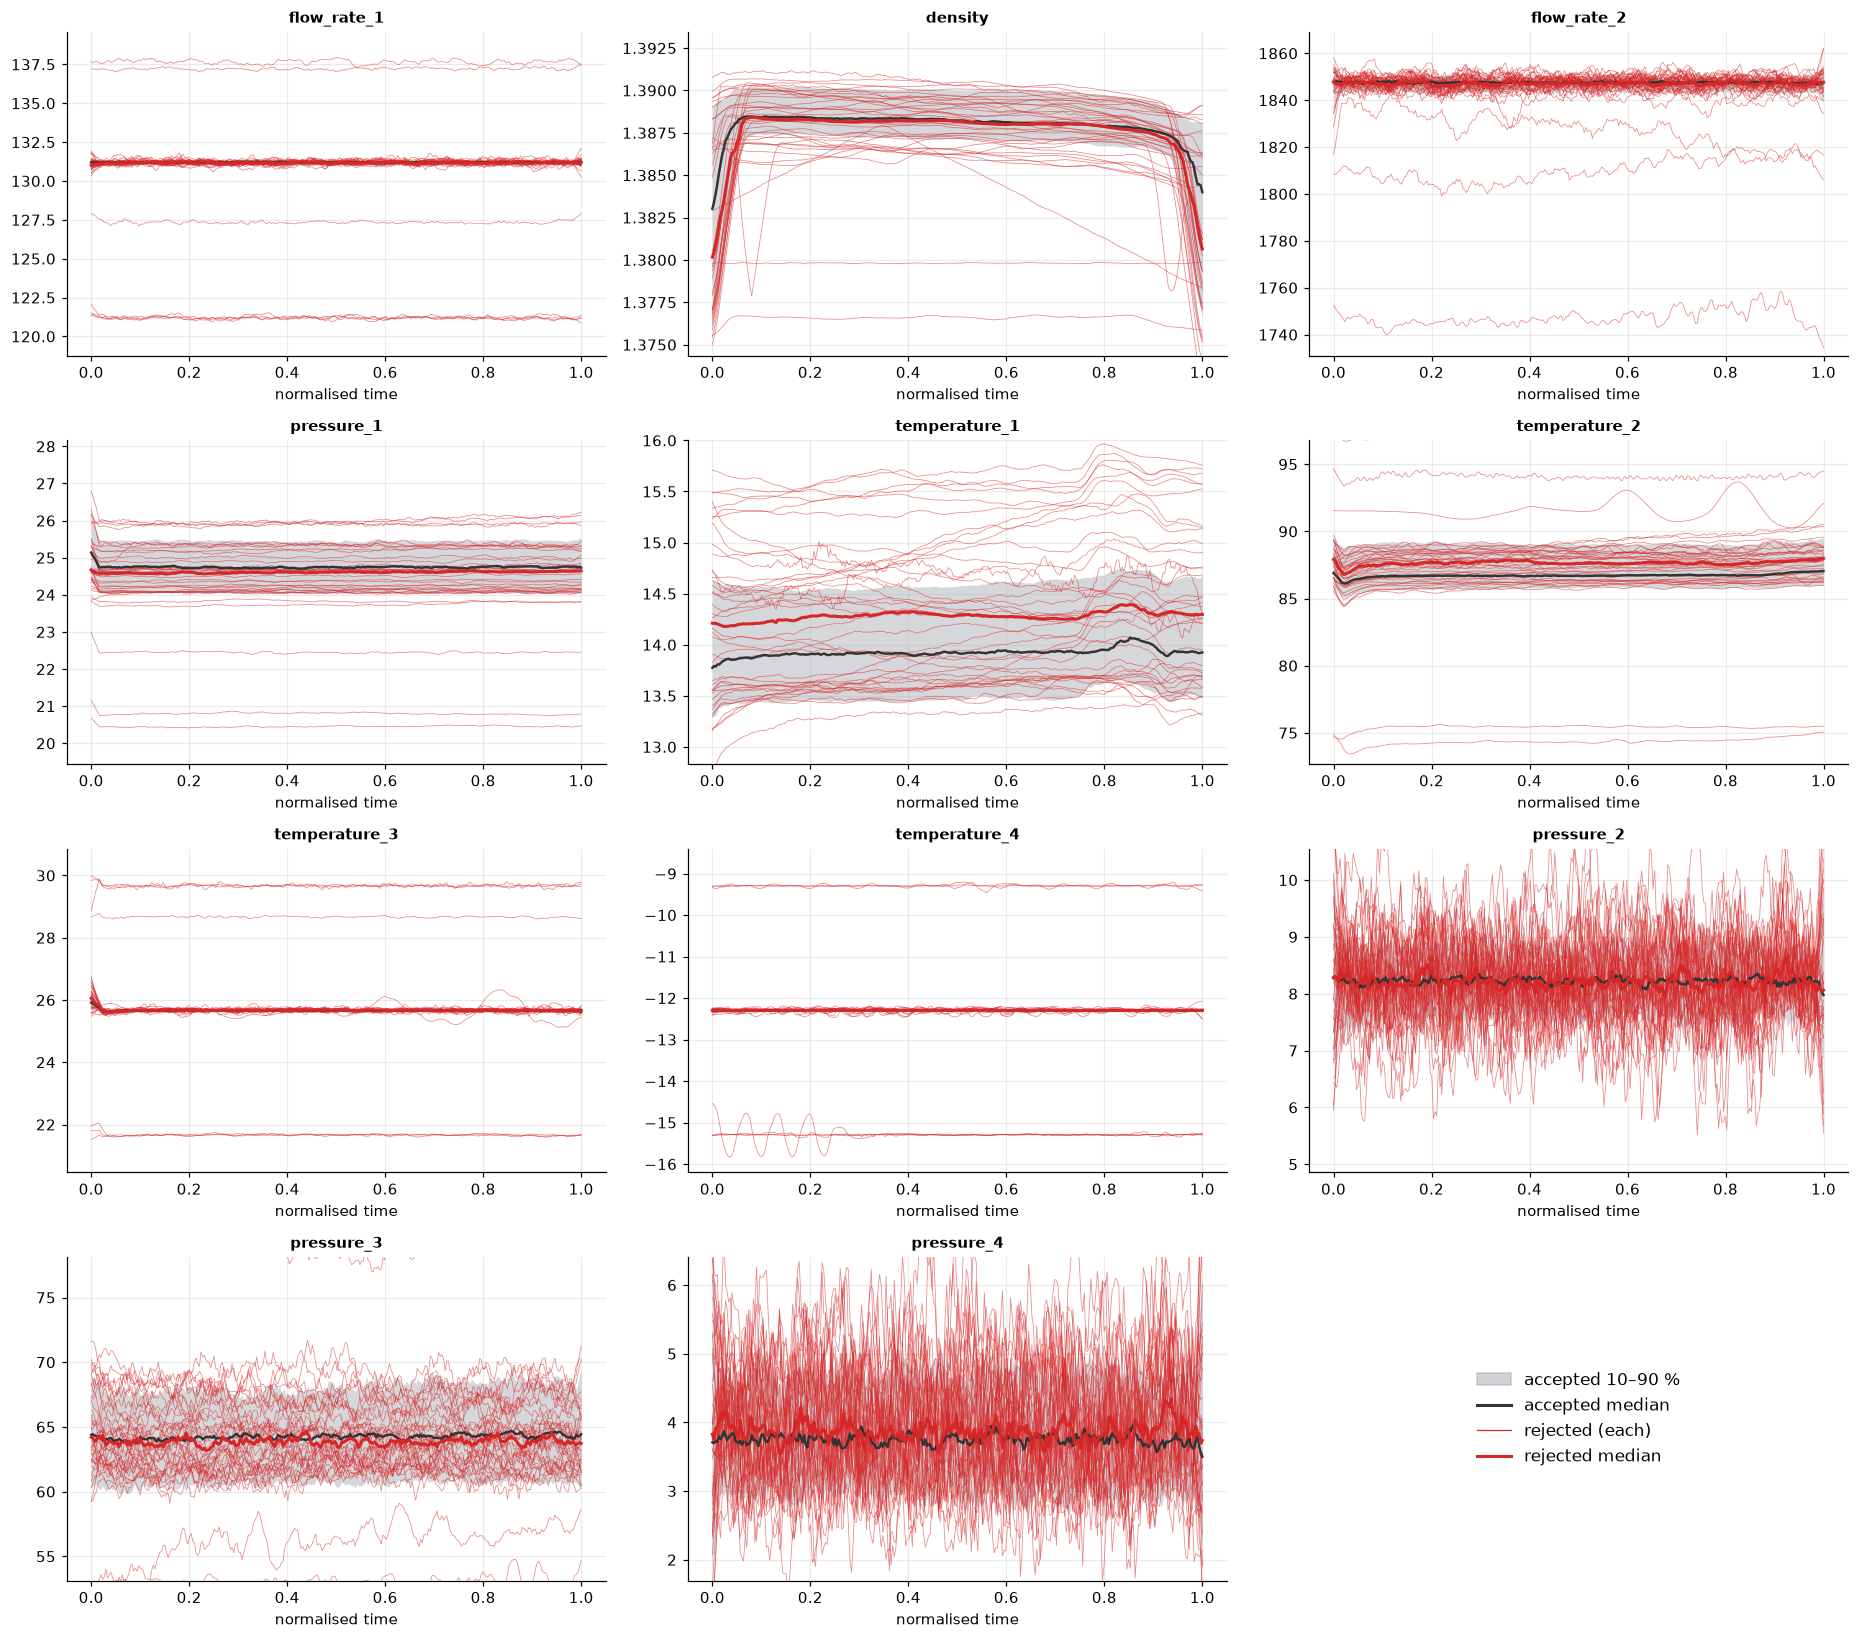

In [3]:
fig,axs=plt.subplots(4,3,figsize=(17,15)); 
for ax,v in zip(axs.ravel(),V):
    A=sm(Xc[v]); ax.fill_between(g,np.percentile(A[acc],10,axis=0),np.percentile(A[acc],90,axis=0),color=GREY,alpha=.35,lw=0)
    for r in A[rej]: ax.plot(g,r,color=RED,lw=.5,alpha=.55)
    ax.plot(g,np.median(A[acc],axis=0),color="#333",lw=1.6); ax.plot(g,np.median(A[rej],axis=0),color=RED,lw=2)
    ax.set_ylim(*robust_ylim(A)); ax.set_title(v); ax.set_xlabel("normalised time")
axs.ravel()[-1].axis("off")
axs.ravel()[-1].legend(handles=[plt.Rectangle((0,0),1,1,color=GREY,alpha=.4),plt.Line2D([],[],color="#333",lw=2),plt.Line2D([],[],color=RED,lw=.8),plt.Line2D([],[],color=RED,lw=2)],labels=["accepted 10–90 %","accepted median","rejected (each)","rejected median"],loc="center",fontsize=11)
plt.tight_layout(); plt.show()

## 3. Does the *level* of a variable separate the classes?
One dot per batch (its median over the whole batch). Boxes show the spread of each class.

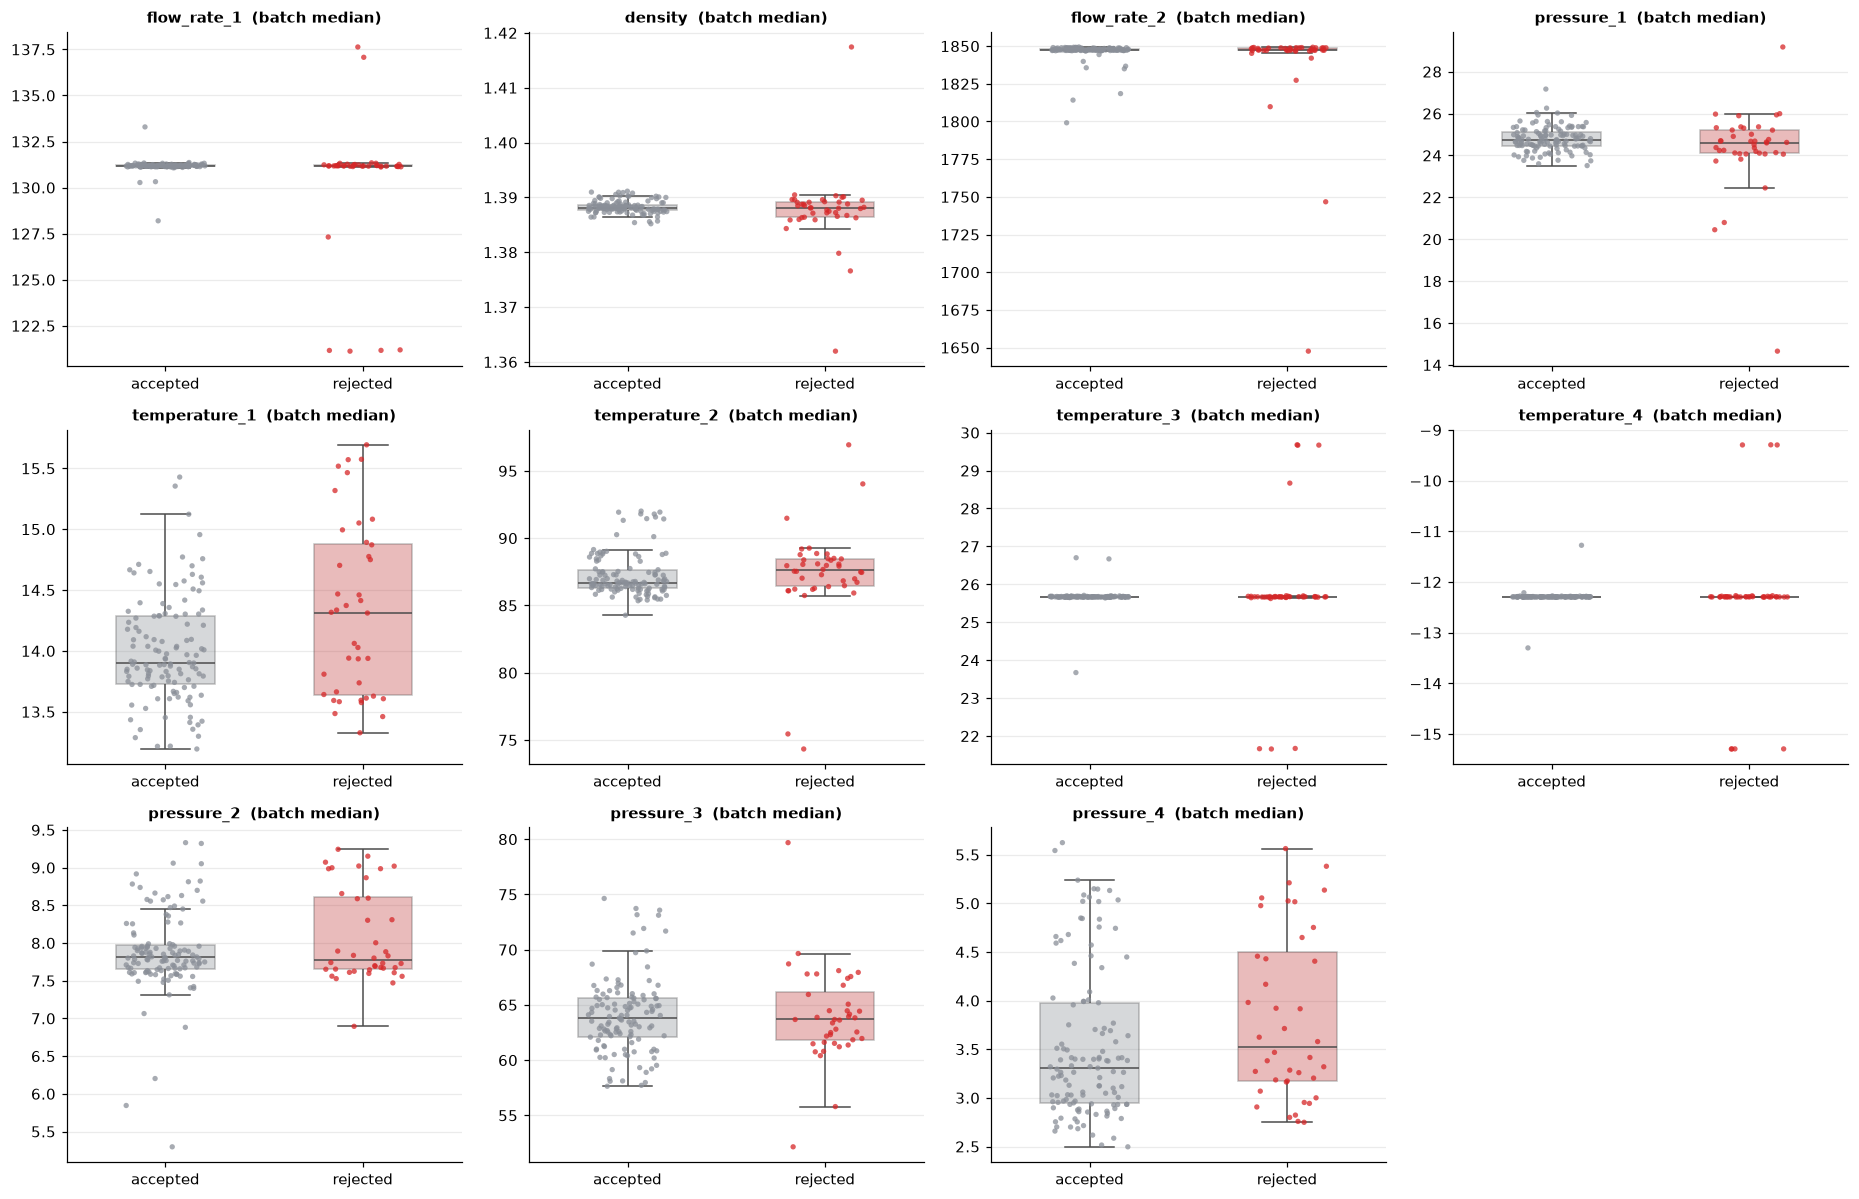

In [4]:
fig,axs=plt.subplots(3,4,figsize=(17,11))
lab_s=pd.Series(yc,index=ids)
for ax,v in zip(axs.ravel(),V):
    d=pd.DataFrame({"v":med[v].values,"class":yc})
    sns.boxplot(data=d,x="class",y="v",hue="class",legend=False,palette=PAL,order=["accepted","rejected"],ax=ax,width=.5,fliersize=0,boxprops=dict(alpha=.35))
    sns.stripplot(data=d,x="class",y="v",hue="class",legend=False,palette=PAL,order=["accepted","rejected"],ax=ax,size=3.5,alpha=.75,jitter=.2)
    ax.set_title(v+"  (batch median)"); ax.set_xlabel(""); ax.set_ylabel("")
axs.ravel()[-1].axis("off"); plt.tight_layout(); plt.show()

## 4. Does the *noisiness* of a variable separate the classes?
Within-batch standard deviation (log scale), one dot per batch.

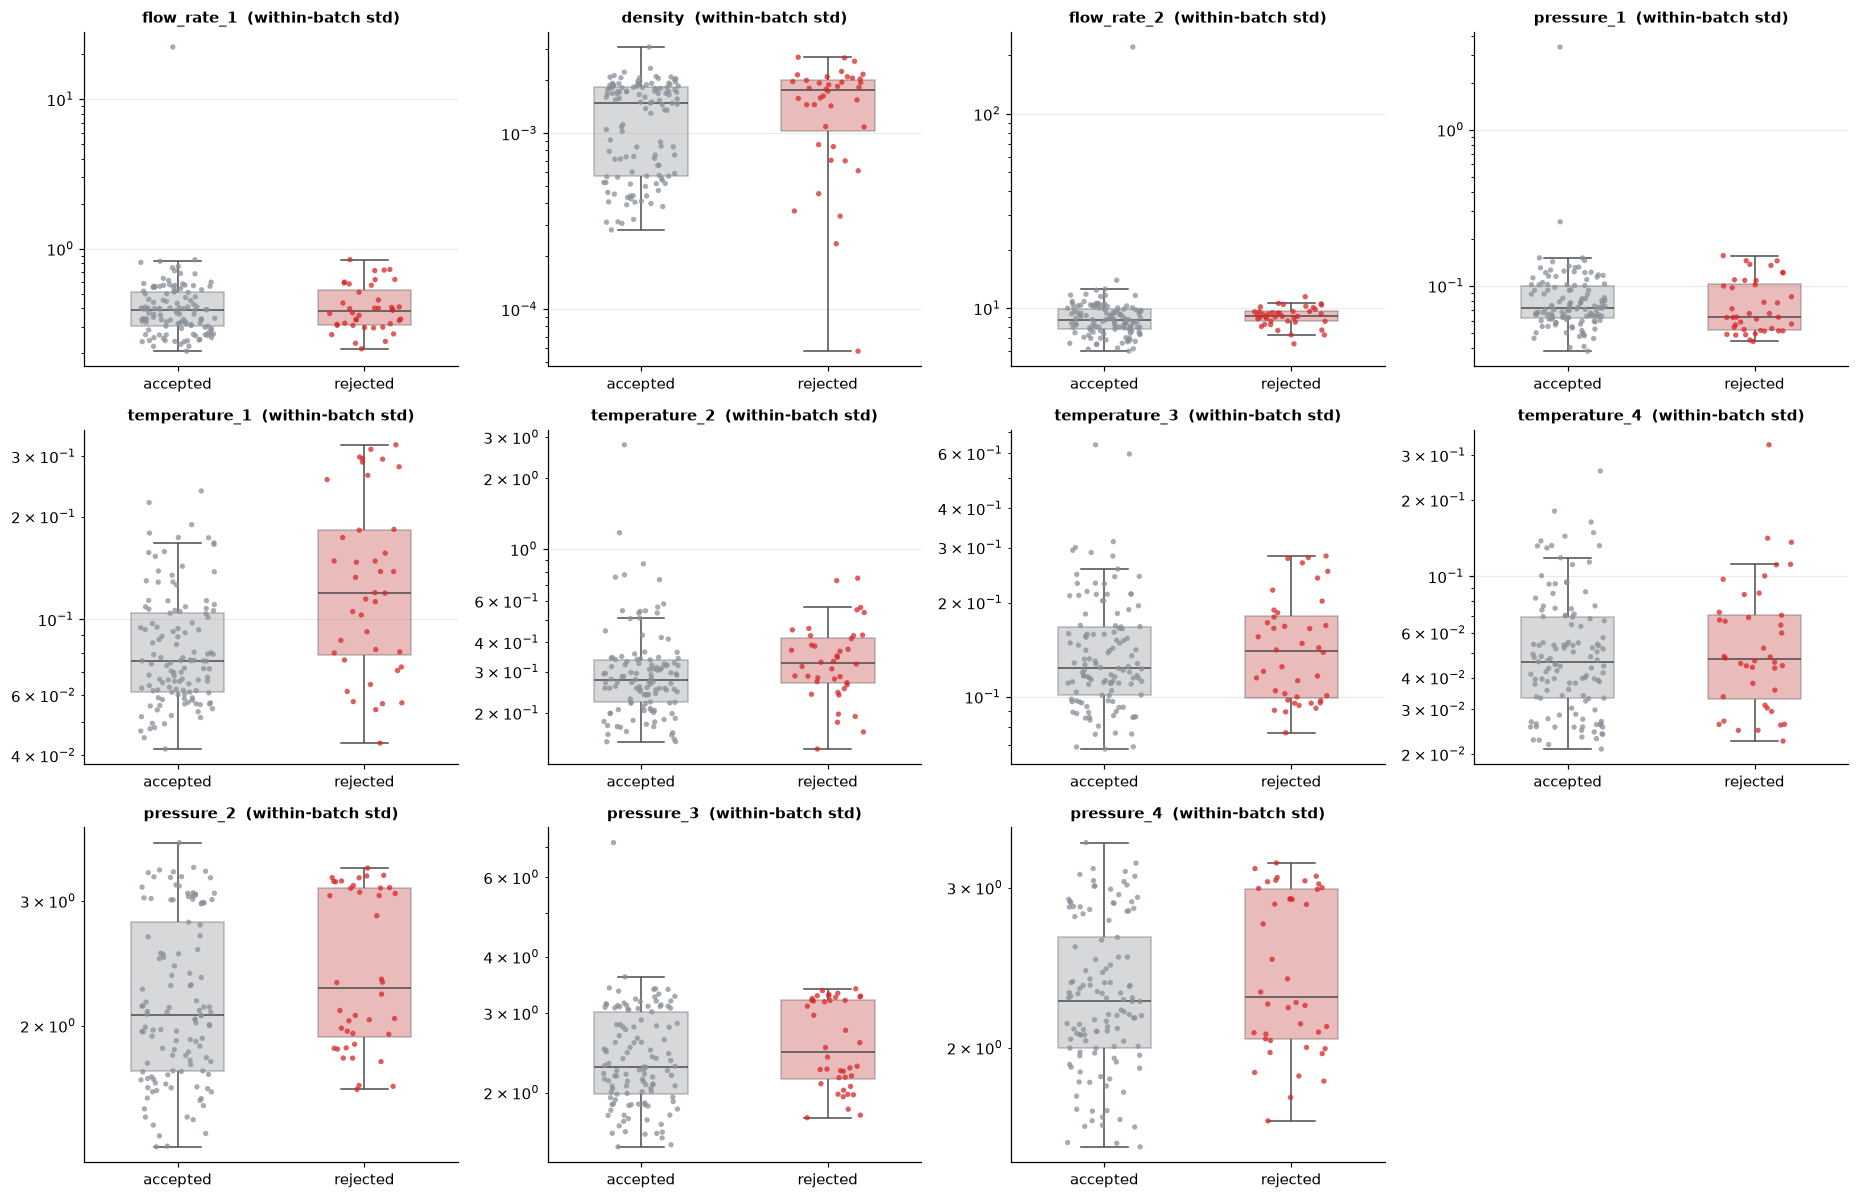

In [5]:
fig,axs=plt.subplots(3,4,figsize=(17,11))
for ax,v in zip(axs.ravel(),V):
    d=pd.DataFrame({"v":sd[v].values,"class":yc})
    sns.boxplot(data=d,x="class",y="v",hue="class",legend=False,palette=PAL,order=["accepted","rejected"],ax=ax,width=.5,fliersize=0,boxprops=dict(alpha=.35))
    sns.stripplot(data=d,x="class",y="v",hue="class",legend=False,palette=PAL,order=["accepted","rejected"],ax=ax,size=3.5,alpha=.75,jitter=.2)
    ax.set_yscale("log"); ax.set_title(v+"  (within-batch std)"); ax.set_xlabel(""); ax.set_ylabel("")
axs.ravel()[-1].axis("off"); plt.tight_layout(); plt.show()

## 5. Which batches are outliers, and in which variable?
Heatmap of |batch median − accepted centre| / threshold, where the threshold is the largest deviation seen among accepted batches (the baseline rule). **Values above 1 (dark) are outside anything seen in accepted batches.** Rows: rejected batches first, then accepted ones.

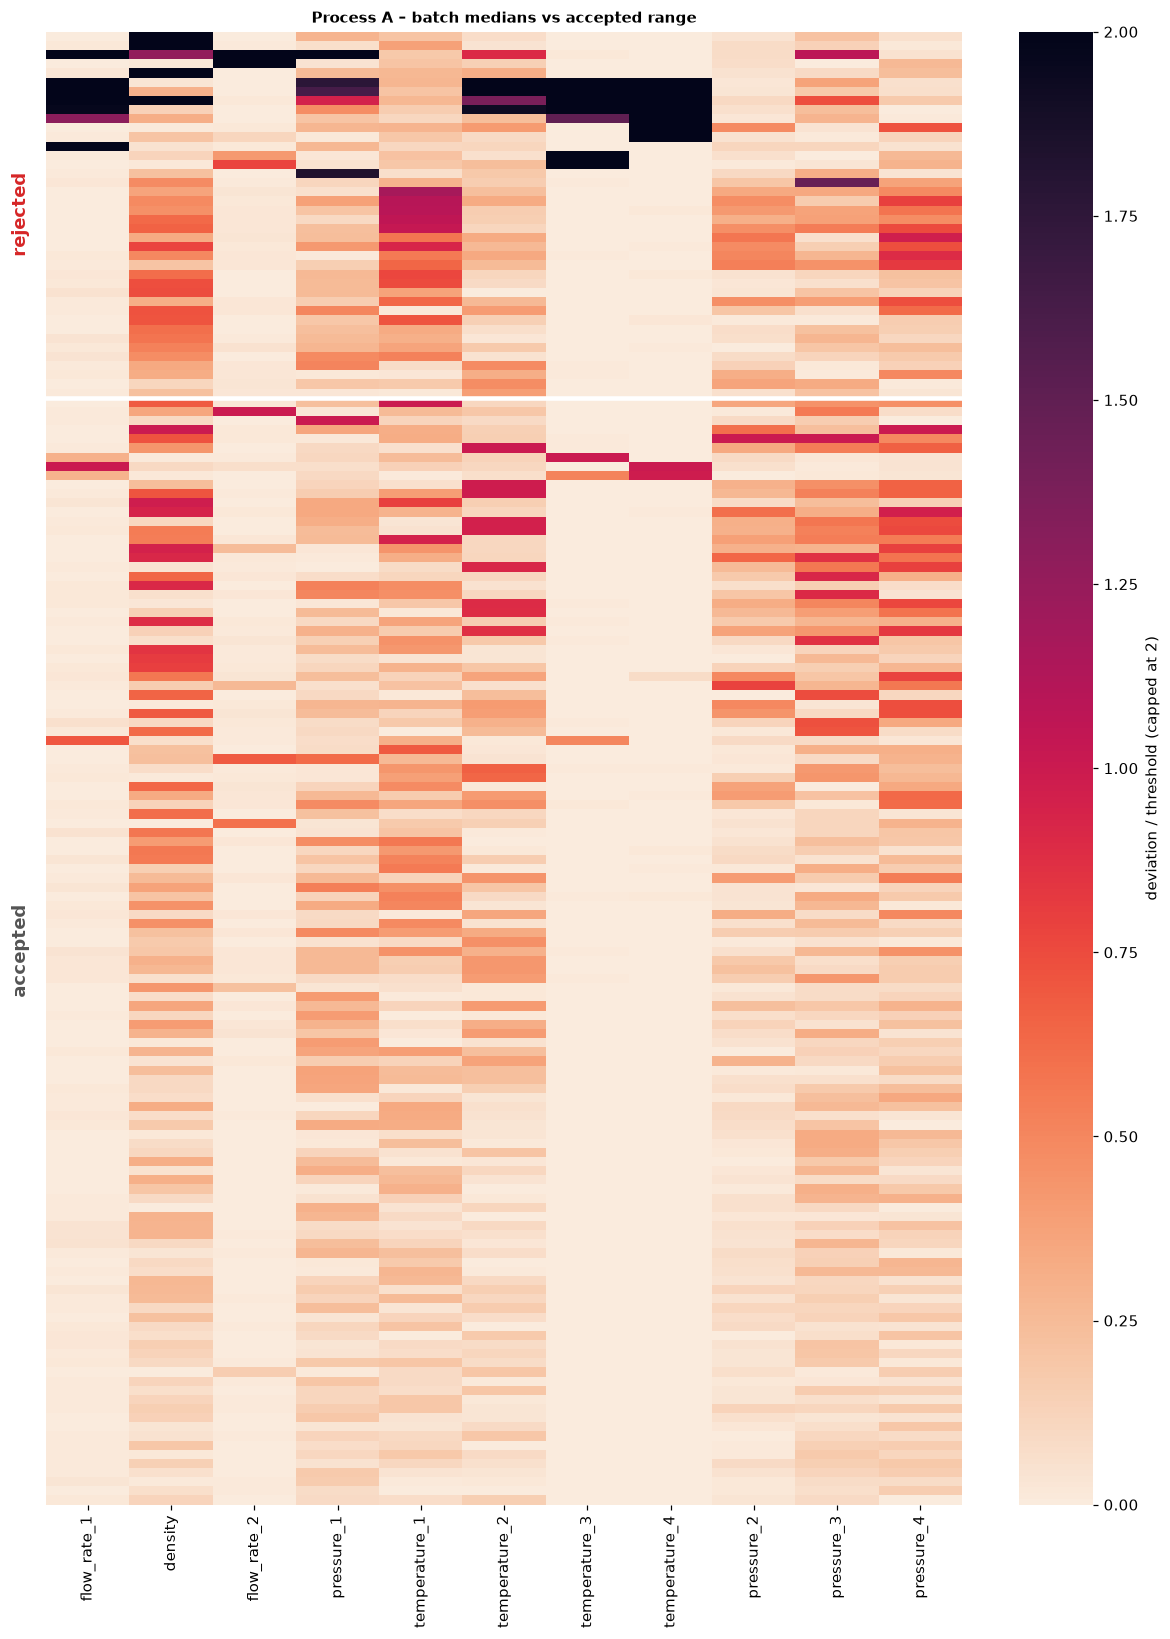

rejected flagged: 22/40 | accepted flagged (in-sample, 0 by construction): 0/121


In [6]:
centre=med[acc].median(); thr=(med[acc]-centre).abs().max()
dev=((med-centre).abs()/thr)
order=list(dev[rej].max(axis=1).sort_values(ascending=False).index)+list(dev[acc].max(axis=1).sort_values(ascending=False).index)
fig,ax=plt.subplots(1,1,figsize=(11,15))
sns.heatmap(dev.loc[order].clip(upper=2),cmap="rocket_r",vmin=0,vmax=2,ax=ax,cbar_kws=dict(label="deviation / threshold (capped at 2)"),yticklabels=False,linewidths=0)
ax.axhline(rej.sum(),color="white",lw=3); ax.text(-.2,rej.sum()/2,"rejected",rotation=90,va="center",ha="right",color=RED,fontweight="bold",fontsize=12)
ax.text(-.2,rej.sum()+acc.sum()/2,"accepted",rotation=90,va="center",ha="right",color="#555",fontweight="bold",fontsize=12)
ax.set_title("Process A – batch medians vs accepted range"); ax.set_ylabel(""); ax.grid(False); plt.tight_layout(); plt.show()
flag=(dev>1).any(axis=1)
print(f"rejected flagged: {flag[rej].sum()}/{rej.sum()} | accepted flagged (in-sample, 0 by construction): {flag[acc].sum()}/{acc.sum()}")

## 6. Batch number order: drift over the campaign?
If the process drifts over time (sensor ageing, raw material lots), batch number would show structure. Left: where the rejected batches are in the batch sequence. Right: a rolling rejection rate.

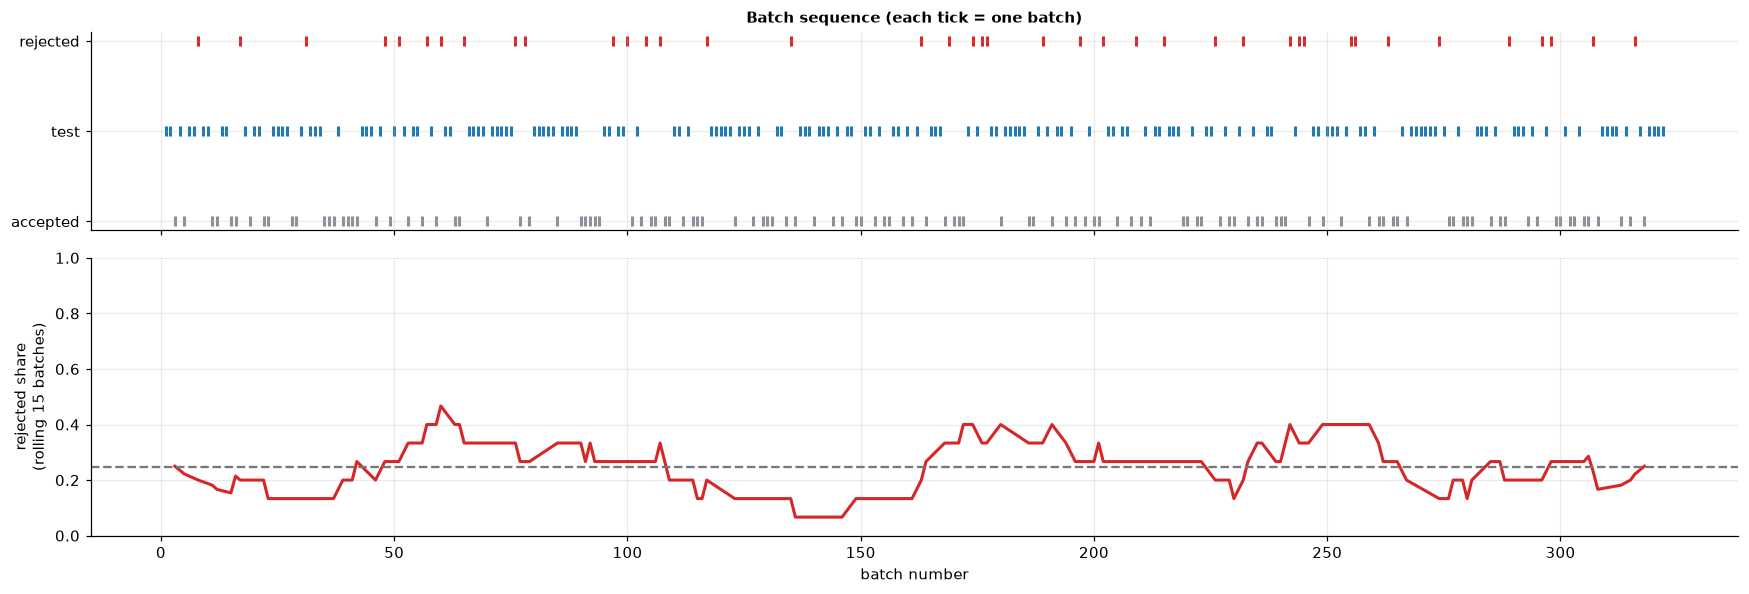

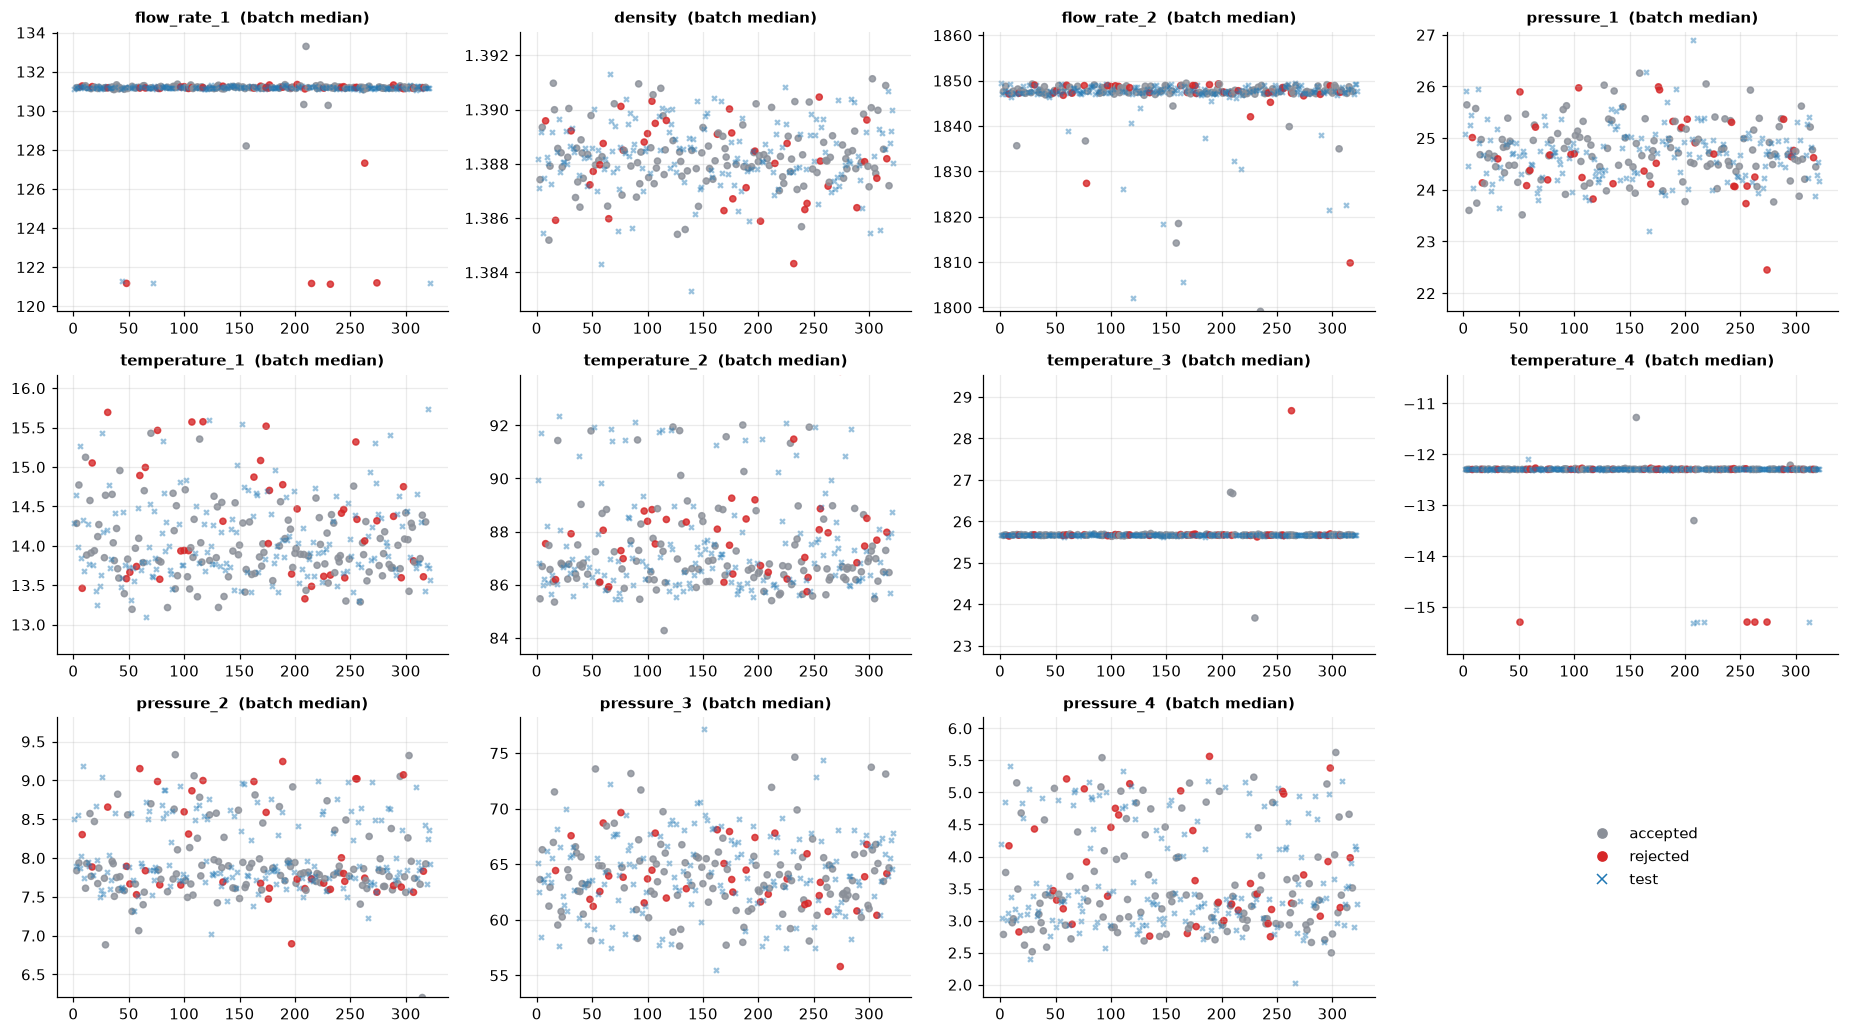

In [7]:
bn=bnum(ids); o=np.argsort(bn)
fig,ax=plt.subplots(2,1,figsize=(16,5.5),sharex=True,gridspec_kw=dict(height_ratios=[1,1.4]))
ax[0].scatter(bn,np.where(rej,1,0),c=[RED if r else GREY for r in rej],s=40,marker="|",linewidths=2)
tb=bnum(idst); ax[0].scatter(tb,np.full(len(tb),.5),c=BLUE,s=40,marker="|",linewidths=2)
ax[0].set_yticks([0,.5,1],["accepted","test","rejected"]); ax[0].set_title("Batch sequence (each tick = one batch)")
w=15; rr=pd.Series(rej[o].astype(float)).rolling(w,center=True,min_periods=5).mean()
ax[1].plot(bn[o],rr,color=RED,lw=2); ax[1].axhline(rej.mean(),color="#777",ls="--"); ax[1].set_ylabel(f"rejected share\n(rolling {w} batches)"); ax[1].set_xlabel("batch number"); ax[1].set_ylim(0,1)
plt.tight_layout(); plt.show()
fig,axs=plt.subplots(3,4,figsize=(17,9.5))
for ax,v in zip(axs.ravel(),V):
    ax.scatter(bn,med[v],c=[RED if r else GREY for r in rej],s=16,alpha=.8); ax.scatter(tb,tmed[v],c=BLUE,s=10,alpha=.45,marker="x")
    ax.set_ylim(*robust_ylim(med[v],2,98,.3)); ax.set_title(v+"  (batch median)")
axs.ravel()[-1].axis("off"); axs.ravel()[-1].legend(handles=[plt.Line2D([],[],marker="o",ls="",color=GREY),plt.Line2D([],[],marker="o",ls="",color=RED),plt.Line2D([],[],marker="x",ls="",color=BLUE)],labels=["accepted","rejected","test"],loc="center")
plt.tight_layout(); plt.show()

## 7. Batches 101–104
(Smoothed curves. `A_102` is a test batch, so it is dashed and has no label.)

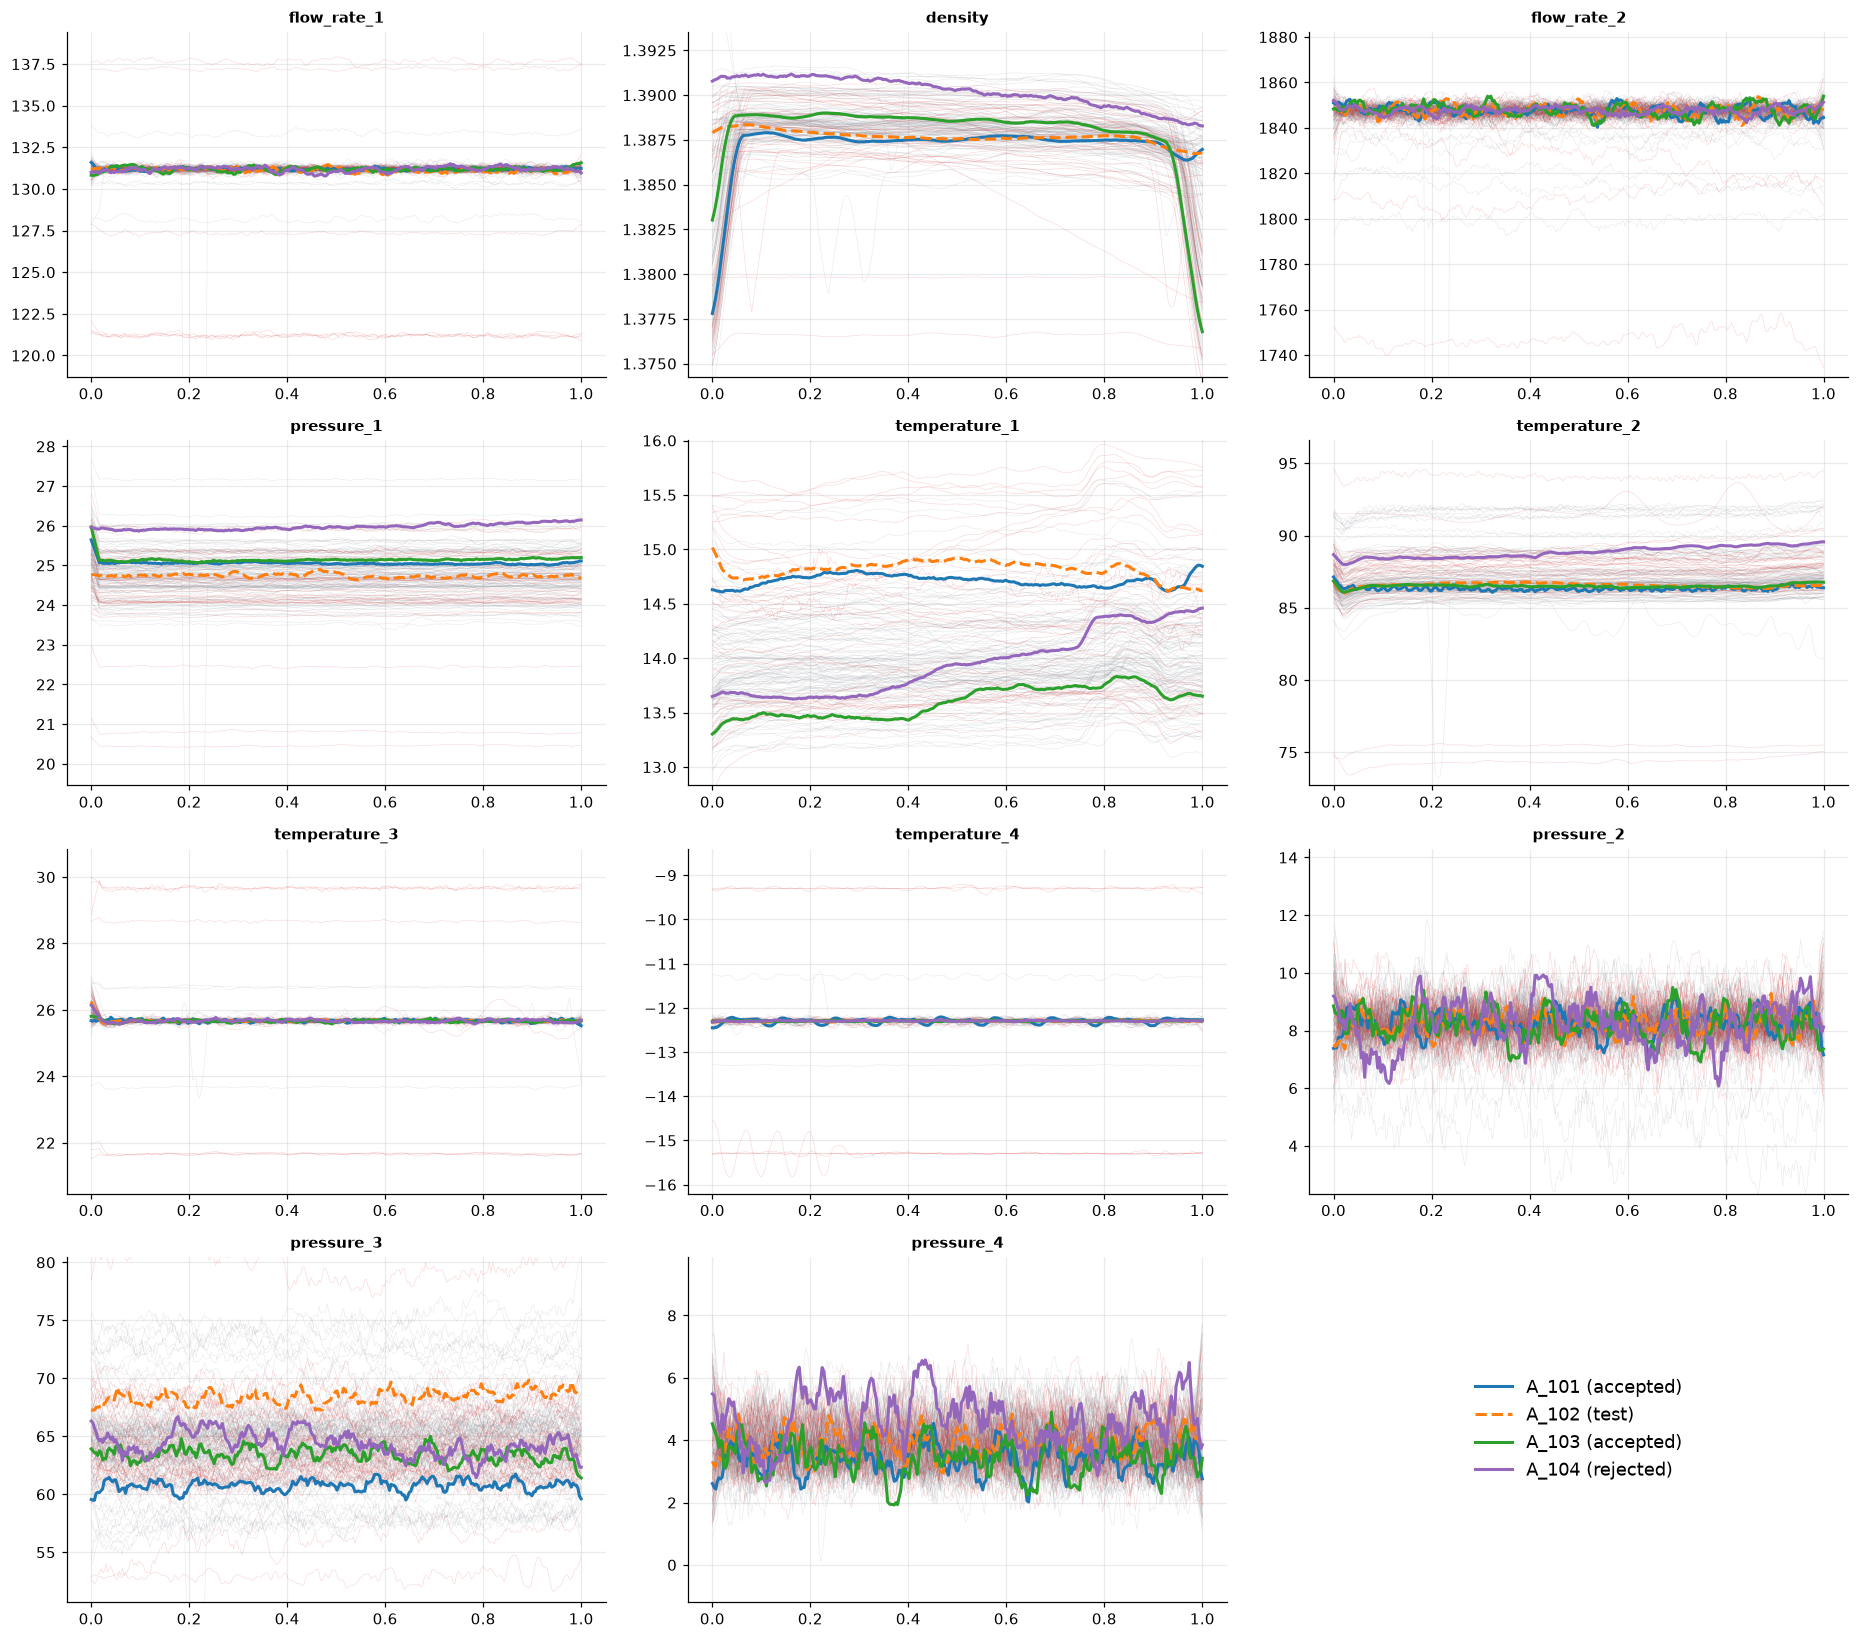

In [8]:
HL={"A_101":"#1f77b4","A_102":"#ff7f0e","A_103":"#2ca02c","A_104":"#9467bd"}
fig,axs=plt.subplots(4,3,figsize=(17,15))
for ax,v in zip(axs.ravel(),V):
    for k in (acc,rej): 
        for r in sm(Xc[v])[k]: ax.plot(g,r,color=GREY if k is acc else RED,lw=.4,alpha=.18)
    for b,col in HL.items():
        if b in ids: ax.plot(g,sm(Xc[v])[ids.index(b)],color=col,lw=2,label=f"{b} ({y[b]})")
        elif b in idst: ax.plot(gt,sm(Xt[v])[idst.index(b)],color=col,lw=2,ls="--",label=f"{b} (test)")
    ax.set_ylim(*robust_ylim(Xc[v])); ax.set_title(v)
h,l=axs[0,0].get_legend_handles_labels(); axs.ravel()[-1].axis("off"); axs.ravel()[-1].legend(h,l,loc="center",fontsize=12)
plt.tight_layout(); plt.show()

## 8. Batches in feature space (PCA)
Each batch is summarised by its median, standard deviation and trend (slope over normalised time) in every variable, robust-scaled, then projected to 2D. If classes form separate clouds, a model has something to learn.

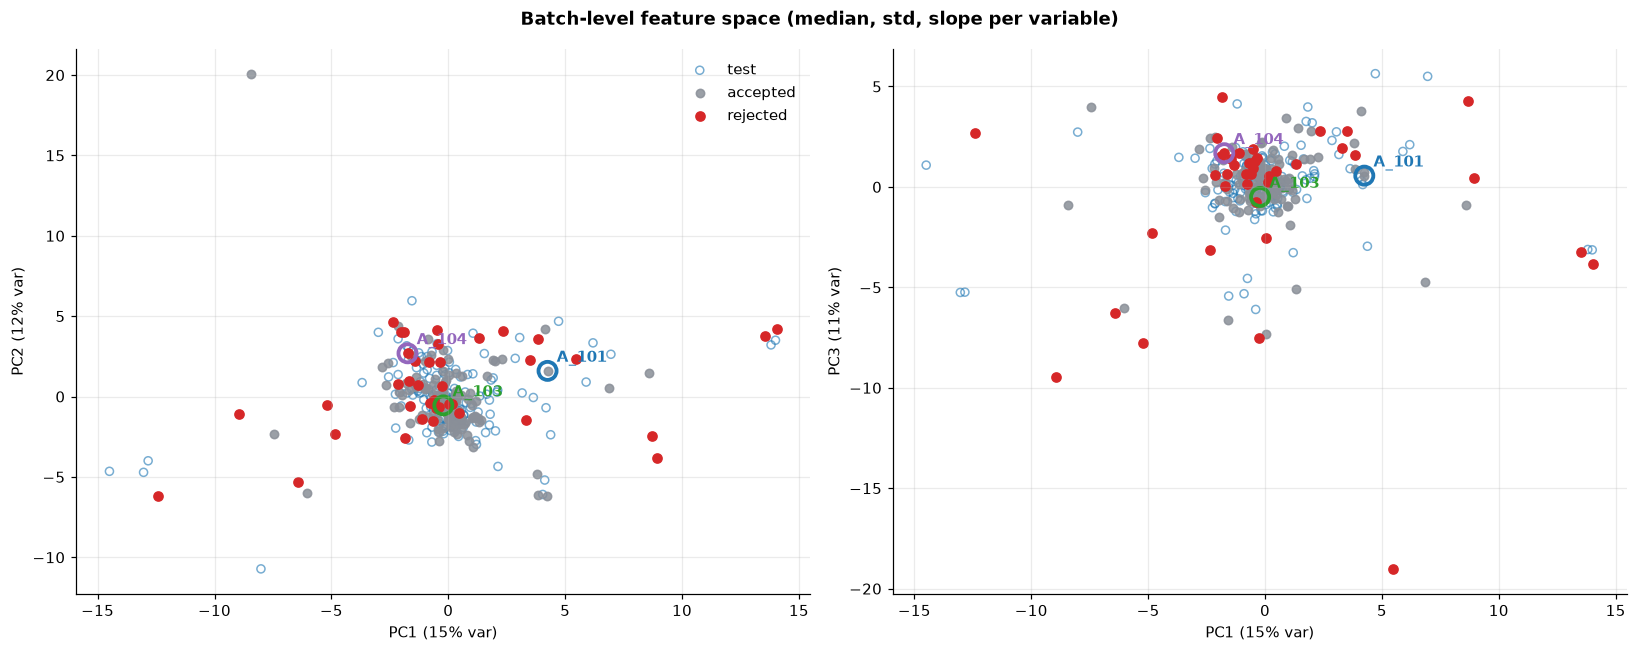

Top loadings


,PC1,PC2,PC3
temperature_4_med,0.58,0.36,0.27
temperature_3_med,-0.56,-0.17,0.01
flow_rate_1_med,-0.29,-0.07,0.54
flow_rate_2_slope,-0.26,0.42,-0.51
temperature_2_med,-0.23,0.03,-0.01
flow_rate_2_med,-0.18,0.21,0.41
pressure_1_med,-0.12,-0.09,0.23
temperature_3_std,-0.12,0.27,-0.03


In [9]:
def feats(df):
    gb=df.groupby("batch_id"); f=pd.concat([gb[V].median().add_suffix("_med"),gb[V].std().add_suffix("_std")],axis=1)
    sl=df.groupby("batch_id").apply(lambda x:pd.Series({v+"_slope":np.polyfit(x.tn,x[v],1)[0] for v in V}),include_groups=False)
    f=f.join(sl); f["len"]=gb.size(); return f
Fc=feats(cal).loc[ids]; Ft=feats(test).loc[idst]
sc=RobustScaler().fit(Fc); Zc=np.clip(sc.transform(Fc),-8,8); Zt=np.clip(sc.transform(Ft),-8,8)
pca=PCA(3).fit(Zc); Pc,Pt=pca.transform(Zc),pca.transform(Zt)
fig,ax=plt.subplots(1,2,figsize=(15,6))
for a,(i,j) in zip(ax,[(0,1),(0,2)]):
    a.scatter(Pt[:,i],Pt[:,j],facecolors="none",edgecolors=BLUE,s=28,alpha=.6,label="test")
    a.scatter(Pc[acc,i],Pc[acc,j],c=GREY,s=30,alpha=.85,label="accepted"); a.scatter(Pc[rej,i],Pc[rej,j],c=RED,s=36,label="rejected")
    for b,col in HL.items():
        if b in ids: k=ids.index(b); a.scatter(Pc[k,i],Pc[k,j],s=140,facecolors="none",edgecolors=col,lw=2.5); a.annotate(b,(Pc[k,i],Pc[k,j]),xytext=(6,6),textcoords="offset points",color=col,fontweight="bold")
    a.set_xlabel(f"PC{i+1} ({100*pca.explained_variance_ratio_[i]:.0f}% var)"); a.set_ylabel(f"PC{j+1} ({100*pca.explained_variance_ratio_[j]:.0f}% var)")
ax[0].legend(); plt.suptitle("Batch-level feature space (median, std, slope per variable)",fontweight="bold"); plt.tight_layout(); plt.show()
load=pd.DataFrame(pca.components_.T,index=Fc.columns,columns=["PC1","PC2","PC3"]); print("Top loadings"); display(load.reindex(load.PC1.abs().sort_values(ascending=False).index).head(8).round(2))

## 9. Which summary features separate the classes best?
Univariate separability (AUC; 0.5 = useless, 1 = perfect; direction ignored) for every per-batch feature.

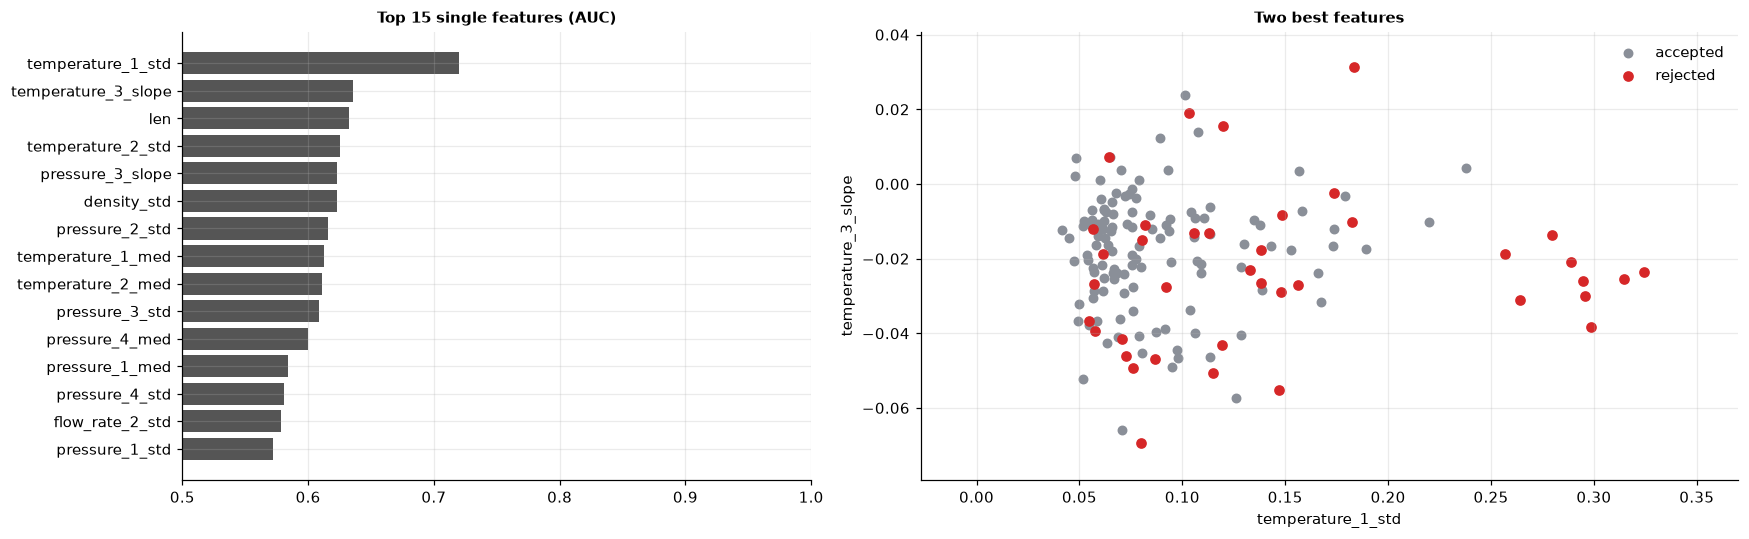

In [10]:
from sklearn.metrics import roc_auc_score
auc=pd.Series({c:roc_auc_score(rej,Fc[c]) for c in Fc.columns}); auc=(auc-.5).abs()+.5
top=auc.sort_values(ascending=False).head(15)
fig,ax=plt.subplots(1,2,figsize=(16,5),gridspec_kw=dict(width_ratios=[1,1.3]))
ax[0].barh(top.index[::-1],top.values[::-1],color="#555"); ax[0].set_xlim(.5,1); ax[0].set_title("Top 15 single features (AUC)")
best=list(top.index[:2]); 
ax[1].scatter(Fc.loc[acc,best[0]],Fc.loc[acc,best[1]],c=GREY,s=30,label="accepted"); ax[1].scatter(Fc.loc[rej,best[0]],Fc.loc[rej,best[1]],c=RED,s=36,label="rejected")
ax[1].set_xlabel(best[0]); ax[1].set_ylabel(best[1]); ax[1].set_title("Two best features"); ax[1].legend()
ax[1].set_xlim(*robust_ylim(Fc[best[0]],2,98,.3)); ax[1].set_ylim(*robust_ylim(Fc[best[1]],2,98,.3))
plt.tight_layout(); plt.show()

## 10. Relationships between variables

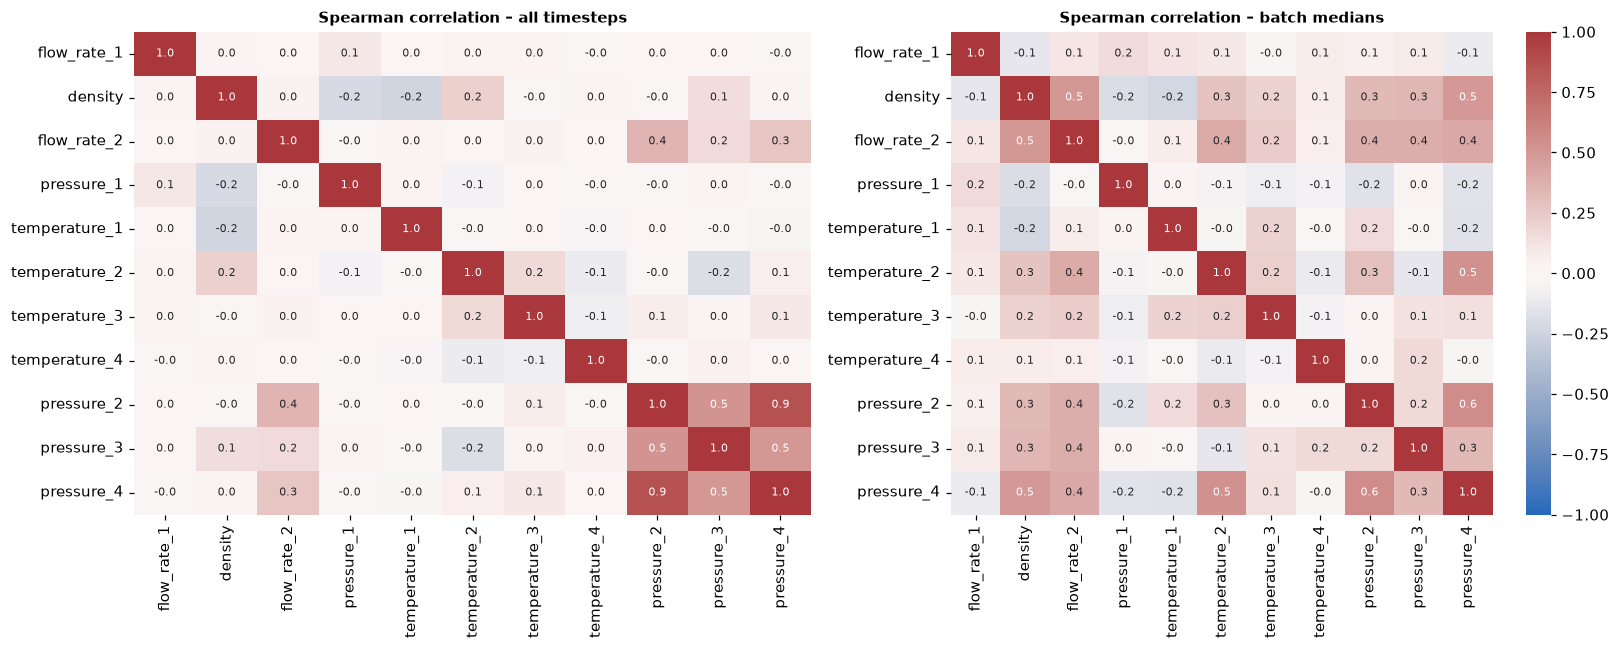

In [11]:
fig,ax=plt.subplots(1,2,figsize=(15,6))
sub=cal.sample(60000,random_state=0)[V]
sns.heatmap(sub.corr(method="spearman"),cmap="vlag",center=0,vmin=-1,vmax=1,annot=True,fmt=".1f",annot_kws=dict(size=7),ax=ax[0],cbar=False); ax[0].set_title("Spearman correlation – all timesteps"); ax[0].grid(False)
sns.heatmap(med.corr(method="spearman"),cmap="vlag",center=0,vmin=-1,vmax=1,annot=True,fmt=".1f",annot_kws=dict(size=7),ax=ax[1]); ax[1].set_title("Spearman correlation – batch medians"); ax[1].grid(False)
plt.tight_layout(); plt.show()

## 11. Calibration vs test: same distribution?
Batch medians standardised with the calibration accepted batches' median / IQR. If the test batches looked very different, a model trained on calibration could fail.

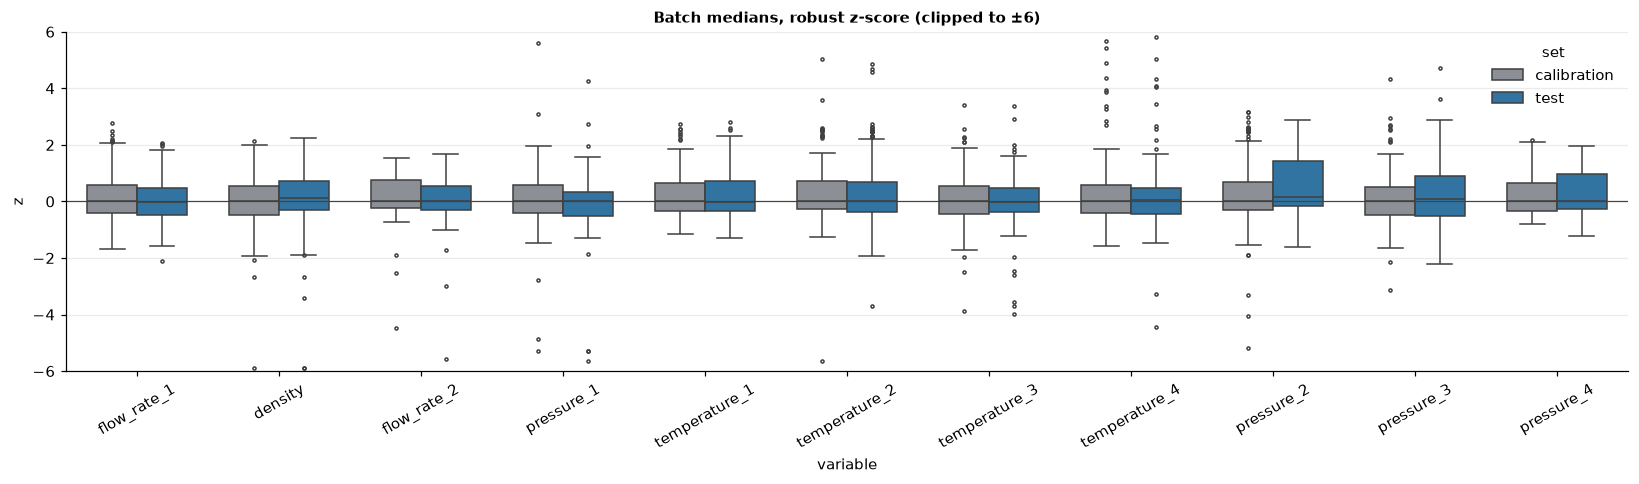

In [12]:
ctr=med.median(); iqr=(med.quantile(.75)-med.quantile(.25)); zc=(med-ctr)/iqr; zt=(tmed-ctr)/iqr
d=pd.concat([zc.assign(set="calibration"),zt.assign(set="test")]).melt(id_vars="set",var_name="variable",value_name="z")
fig,ax=plt.subplots(figsize=(15,4.5)); sns.boxplot(data=d,x="variable",y="z",hue="set",palette={"calibration":GREY,"test":BLUE},ax=ax,fliersize=2,width=.7)
ax.set_ylim(-6,6); ax.axhline(0,color="#444",lw=.8); ax.set_title("Batch medians, robust z-score (clipped to ±6)"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

## 12. Unusual batches up close
The shortest batches and the batches with in-run glitches.

{'A_232': 196, 'A_149': 1166, 'A_215': 1720, 'A_285': 1794} ['rejected', 'accepted', 'rejected', 'accepted']


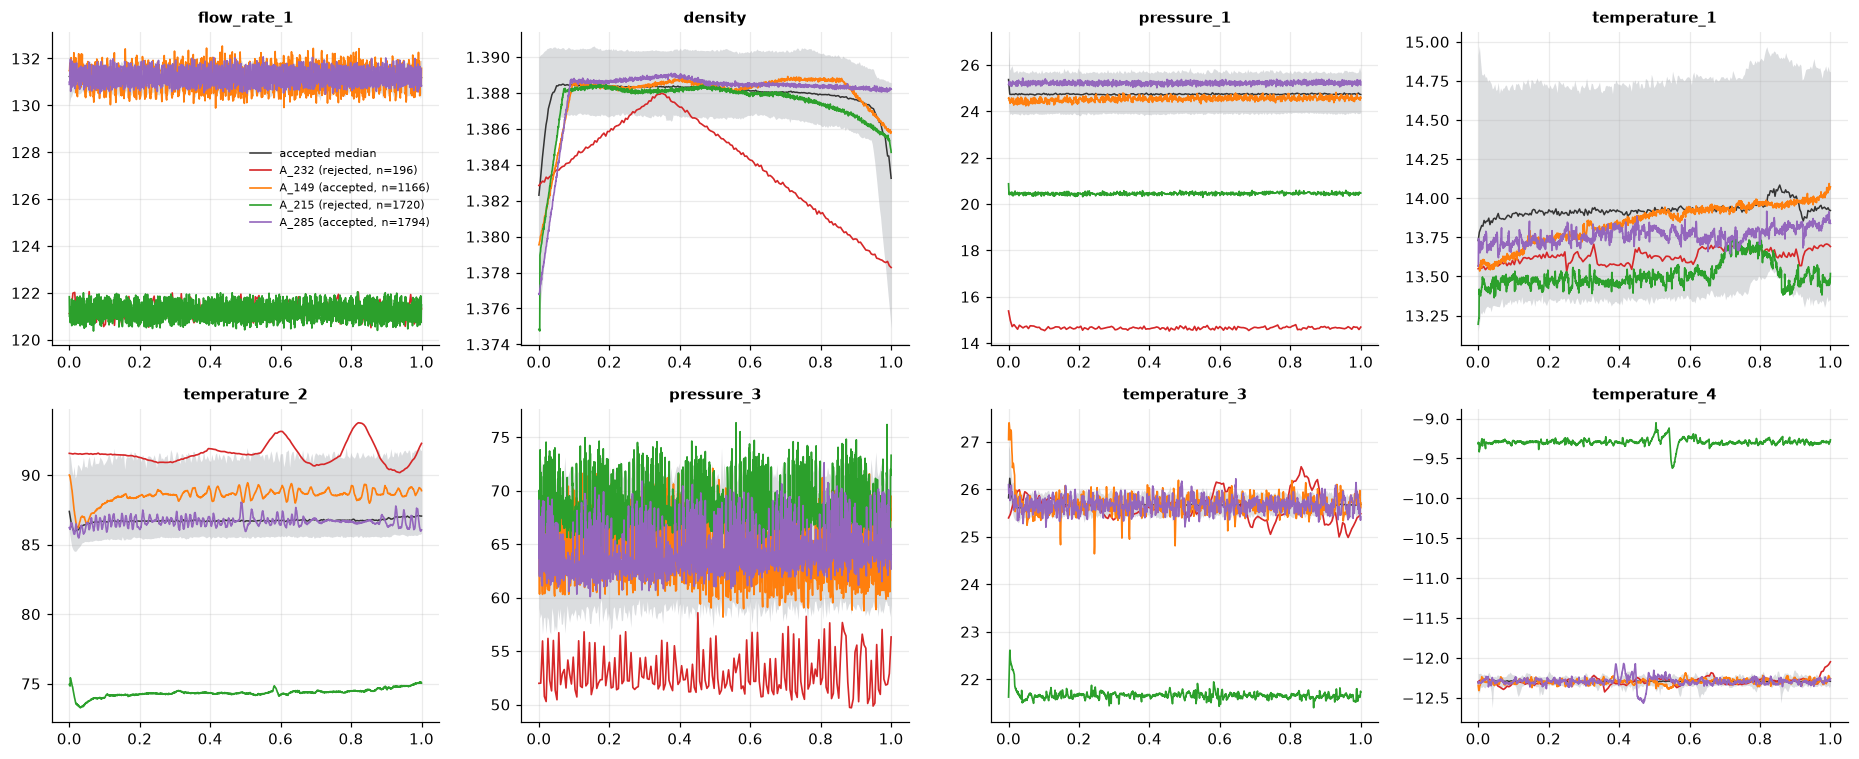

In [13]:
short=list(n_cal.nsmallest(4).index); print(n_cal[short].to_dict(), [y[b] for b in short])
fig,axs=plt.subplots(2,4,figsize=(17,7))
for ax,v in zip(axs.ravel(),["flow_rate_1","density","pressure_1","temperature_1","temperature_2","pressure_3","temperature_3","temperature_4"]):
    ax.plot(g,np.median(Xc[v][acc],0),color="#333",lw=1,label="accepted median"); ax.fill_between(g,np.percentile(Xc[v][acc],5,axis=0),np.percentile(Xc[v][acc],95,axis=0),color=GREY,alpha=.3,lw=0)
    for b,col in zip(short,["#d62728","#ff7f0e","#2ca02c","#9467bd"]):
        x=cal[cal.batch_id==b]; ax.plot(x.tn,x[v],color=col,lw=1.1,label=f"{b} ({y[b]}, n={n_cal[b]})")
    ax.set_title(v)
axs[0,0].legend(fontsize=7); plt.tight_layout(); plt.show()